# Section 3: Variable Selection and Model Development

We compare predictive screening, subset-selection criteria and economic reasoning to develop three OLS specifications on the same sample.


<a id="section-3a"></a>

## 3(a) Boruta Algorithm


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display, Markdown

%matplotlib inline

root = next((folder for folder in [Path.cwd(), *Path.cwd().parents]
             if (folder / "data/processed/parking_cross_section.csv").is_file()), None)
if root is None:
    raise FileNotFoundError("The project data/processed/parking_cross_section.csv file is required.")
parking_full = pd.read_csv(root / "data/processed/parking_cross_section.csv",
                          dtype={"SpaceID": str, "GEOID": str})
parking = parking_full.loc[parking_full["RateType"].isin(["FLAT", "TOD"])].copy()
dependent_variable = "occupancy_rate"
candidate_variables = [
    "price_midpoint", "time_limit_hours", "population_density", "median_income",
    "nearby_restaurant_retail_count", "drive_alone_share", "RateType", "MeterType",
    "housing_density", "transit_share", "walk_share", "nearby_business_count"
]
encoded = pd.get_dummies(parking[candidate_variables], drop_first=True, dtype=int)
data = pd.concat([parking[["occupancy_rate"]], encoded], axis=1).dropna().copy()
y = data["occupancy_rate"]
X = data.drop(columns="occupancy_rate")
assert parking_full["SpaceID"].is_unique
assert parking.loc[data.index, "SpaceID"].is_unique
print("Original / FLAT+TOD / common:", len(parking_full), len(parking), len(data))
print("Candidates / common-sample tracts:", X.shape[1], parking.loc[data.index, "GEOID"].nunique())

# Preserve complete table text in report outputs.
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 100)


Original / FLAT+TOD / common: 4139 4060 4016
Candidates / common-sample tracts: 12 45


Random forest depth is 5. Boruta uses automatic tree count, seed 10, 100 maximum iterations, the 100th-percentile shadow-feature threshold, alpha 0.05, and two-step multiple-testing correction (Boruta 0.4.3). Feature importance measures predictive relevance, not OLS significance.

In [2]:

from boruta import BorutaPy
from sklearn.ensemble import RandomForestRegressor

# Prepare data
parking_Y = y.values
parking_X = X.values.astype(np.float32)

# Random forest
rf = RandomForestRegressor(max_depth=5, random_state=10)

# Boruta
boruta = BorutaPy(
    rf,
    n_estimators="auto",
    verbose=0,
    max_iter=100, perc=100, alpha=0.05,
    random_state=10,
    two_step=True
)

boruta.fit(parking_X, parking_Y)

print("\nConfirmed:", list(X.columns[boruta.support_]))



Confirmed: ['price_midpoint', 'time_limit_hours', 'population_density', 'nearby_restaurant_retail_count', 'drive_alone_share', 'housing_density', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD']


In [3]:

boruta_keep = [
    "Confirmed" if c else "Tentative" if t else "Reject"
    for c, t in zip(boruta.support_, boruta.support_weak_)
]

boruta_features = zip(
    X.columns,
    boruta.ranking_,
    boruta_keep
)

for feat in boruta_features:
    print("Feature: {:<35} Rank: {}, Keep: {}".format(
        feat[0], feat[1], feat[2]
    ))


Feature: price_midpoint                      Rank: 1, Keep: Confirmed
Feature: time_limit_hours                    Rank: 1, Keep: Confirmed
Feature: population_density                  Rank: 1, Keep: Confirmed
Feature: median_income                       Rank: 2, Keep: Reject
Feature: nearby_restaurant_retail_count      Rank: 1, Keep: Confirmed
Feature: drive_alone_share                   Rank: 1, Keep: Confirmed
Feature: housing_density                     Rank: 1, Keep: Confirmed
Feature: transit_share                       Rank: 1, Keep: Confirmed
Feature: walk_share                          Rank: 1, Keep: Confirmed
Feature: nearby_business_count               Rank: 1, Keep: Confirmed
Feature: RateType_TOD                        Rank: 1, Keep: Confirmed
Feature: MeterType_Single-Space              Rank: 3, Keep: Reject


In [4]:
boruta_confirmed = list(X.columns[boruta.support_])
boruta_tentative = list(X.columns[boruta.support_weak_])
boruta_rejected = list(X.columns[~(boruta.support_ | boruta.support_weak_)])
display(Markdown(f"Boruta confirms **{len(boruta_confirmed)}** predictors: {', '.join(boruta_confirmed)}. It leaves **{len(boruta_tentative)}** tentative and rejects **{len(boruta_rejected)}**: {', '.join(boruta_rejected) if boruta_rejected else 'none'}. This all-relevant screen evaluates nonlinear predictive importance; confirmation does not imply an individually significant OLS slope or a causal effect."))


Boruta confirms **10** predictors: price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, drive_alone_share, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD. It leaves **0** tentative and rejects **2**: median_income, MeterType_Single-Space. This all-relevant screen evaluates nonlinear predictive importance; confirmation does not imply an individually significant OLS slope or a causal effect.

<a id="section-3b"></a>

## 3(b) Mallows Cp Criterion


In [5]:

full_model = sm.OLS(y, sm.add_constant(X)).fit()

print(full_model.summary())


                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.297
Model:                            OLS   Adj. R-squared:                  0.295
Method:                 Least Squares   F-statistic:                     140.7
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          8.50e-295
Time:                        20:28:59   Log-Likelihood:                 1608.0
No. Observations:                4016   AIC:                            -3190.
Df Residuals:                    4003   BIC:                            -3108.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

In [6]:

from itertools import combinations

sigma2 = full_model.mse_resid

cp_results = []

for k in range(1, len(X.columns) + 1):
    for cols in combinations(X.columns, k):
        model = sm.OLS(y, sm.add_constant(X[list(cols)])).fit()

        rss = sum(model.resid ** 2)
        p = k + 1

        cp = rss / sigma2 - (len(y) - 2 * p)

        cp_results.append({
            "Variables": cols,
            "Number of predictors": k,
            "Cp": cp,
            "Adjusted R2": model.rsquared_adj
        })

cp_results = pd.DataFrame(cp_results)

cp_results.sort_values("Cp").head(10)


,Variables,Number of predictors,Cp,Adjusted R2
4050,"(price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",10,9.949599,0.294709
3950,"(price_midpoint, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",9,10.531400,0.294431
4090,"(price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, drive_alone_share, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",11,11.122981,0.294679
4069,"(price_midpoint, population_density, nearby_restaurant_retail_count, drive_alone_share, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",10,11.578361,0.294423
4088,"(price_midpoint, time_limit_hours, population_density, median_income, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",11,11.773507,0.294564
3582,"(price_midpoint, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD)",8,11.788981,0.294033
3867,"(price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD)",9,11.923251,0.294186
4067,"(price_midpoint, population_density, median_income, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space)",10,12.257728,0.294303
3944,"(price_midpoint, population_density, nearby_restaurant_retail_count, drive_alone_share, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD)",9,12.613759,0.294064
4044,"(price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, drive_alone_share, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD)",10,12.845720,0.294199


In [7]:

best_cp = cp_results.loc[
    cp_results.groupby("Number of predictors")["Cp"].idxmin()
]

best_cp[["Number of predictors", "Cp", "Adjusted R2"]].round(3)


,Number of predictors,Cp,Adjusted R2
0,1,786.957,0.157
13,2,413.784,0.222
93,3,231.578,0.255
414,4,82.641,0.281
956,5,55.239,0.286
1882,6,20.214,0.292
2861,7,17.199,0.293
3582,8,11.789,0.294
3950,9,10.531,0.294
4050,10,9.950,0.295


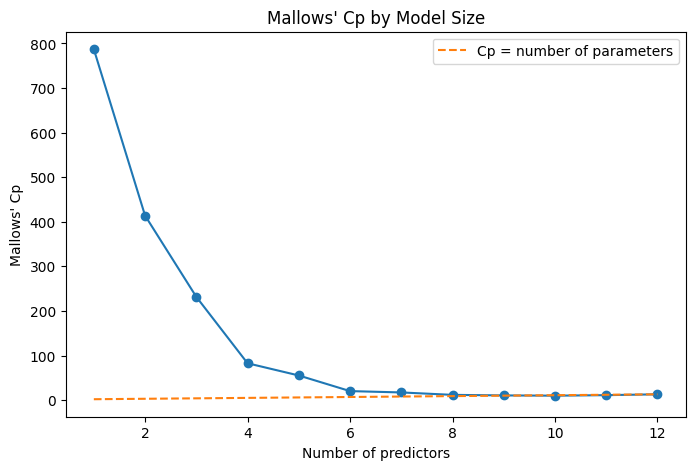

In [8]:

plt.figure(figsize=(8, 5))

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Cp"],
    marker="o"
)

plt.plot(
    best_cp["Number of predictors"],
    best_cp["Number of predictors"] + 1,
    linestyle="--",
    label="Cp = number of parameters"
)

plt.xlabel("Number of predictors")
plt.ylabel("Mallows' Cp")
plt.title("Mallows' Cp by Model Size")
plt.legend()
plt.show()


In [9]:

best_8 = cp_results[
    cp_results["Number of predictors"] == 8
].sort_values("Cp").iloc[0]

print("Best 8-variable model:")
for variable in best_8["Variables"]:
    print(variable)

print("\nMallows' Cp:", round(best_8["Cp"], 3))
print("Adjusted R2:", round(best_8["Adjusted R2"], 3))


Best 8-variable model:
price_midpoint
population_density
nearby_restaurant_retail_count
housing_density
transit_share
walk_share
nearby_business_count
RateType_TOD

Mallows' Cp: 11.789
Adjusted R2: 0.294


Cp uses full-candidate residual variance, with parameter count including the intercept. All 4,095 nonempty subsets are compared. The best-eight display is supporting evidence, not a claim of a global optimum. Cp minimizes a different tradeoff from the significance-based Model 3; we report the selected model’s Cp below rather than claiming it is the minimum. The classical Cp interpretation relies on a common error variance. The heteroskedasticity documented in Section 4 limits that interpretation, so Cp is considered alongside the other selection and validation evidence.

In [10]:
global_cp = cp_results.loc[cp_results["Cp"].idxmin()]
display(Markdown(f"The smallest searched Cp is **{global_cp['Cp']:.3f}**, with **{int(global_cp['Number of predictors'])} slopes** ({int(global_cp['Number of predictors']) + 1} parameters including the intercept). Its predictors are {', '.join(global_cp['Variables'])}. The dashed line in the plot marks Cp equal to the parameter count; the lowest Cp and closeness to this line are related diagnostics, not significance tests."))


The smallest searched Cp is **9.950**, with **10 slopes** (11 parameters including the intercept). Its predictors are price_midpoint, time_limit_hours, population_density, nearby_restaurant_retail_count, housing_density, transit_share, walk_share, nearby_business_count, RateType_TOD, MeterType_Single-Space. The dashed line in the plot marks Cp equal to the parameter count; the lowest Cp and closeness to this line are related diagnostics, not significance tests.

<a id="section-3c"></a>

## 3(c) Variance Inflation Factors


In [11]:

from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X)

vif = pd.DataFrame()
vif["Variable"] = X_vif.columns
vif["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif.round(2)


,Variable,VIF
0,const,110.00
1,price_midpoint,1.71
2,time_limit_hours,1.16
3,population_density,11.98
4,median_income,2.08
5,nearby_restaurant_retail_count,5.91
6,drive_alone_share,2.96
7,housing_density,12.69
8,transit_share,2.32
9,walk_share,3.03


In [12]:

X_reduced = X.drop(columns=[
    "housing_density",
    "nearby_business_count"
])

X_vif_reduced = sm.add_constant(X_reduced)

vif_reduced = pd.DataFrame({
    "Variable": X_vif_reduced.columns,
    "VIF": [
        variance_inflation_factor(X_vif_reduced.values, i)
        for i in range(X_vif_reduced.shape[1])
    ]
})

vif_reduced.round(2)


,Variable,VIF
0,const,109.12
1,price_midpoint,1.64
2,time_limit_hours,1.13
3,population_density,1.18
4,median_income,2.03
5,nearby_restaurant_retail_count,1.75
6,drive_alone_share,2.79
7,transit_share,2.27
8,walk_share,2.49
9,RateType_TOD,1.23


Population/housing density and overlapping business counts inflate full-set VIF. VIF measures slope uncertainty from overlapping predictors, not bias or economic importance. Model 3 includes all full-candidate significant predictors, including both business counts; their VIFs and conditional-composition interpretation are therefore reported. A seven-predictor specification with less overlap is retained as a sensitivity comparison.

<a id="section-3d"></a>

## 3(d) Three Competing Regression Models


**Declared significance rule:** take every non-intercept predictor with conventional two-sided p<0.05 in the original 12-candidate full OLS regression on the common sample. This is a single documented screen, not iterative deletion, a Boruta synonym, or selection tuned on held-out outcomes. Post-selection p-values/CIs are descriptive conditional inference, not selection-adjusted coverage. HC1 significance is also reported as a sensitivity to variance assumptions.

The sensitivity alternative uses price, population density, food-service/retail registrations, time limit, drive-alone share, transit share and TOD pricing. The primary Model 3 follows the declared significance rule.

In [13]:
# Fixed rule: retain EVERY slope with conventional p < 0.05 in the
# original 12-candidate full OLS model, on the same complete-case sample.
# This is one screen, not repeated p-value deletion or hold-out tuning.
full_model = sm.OLS(y, sm.add_constant(X)).fit()
alpha = 0.05
predictors = [v for v in X.columns if full_model.pvalues[v] < alpha]
legacy_predictors = ["price_midpoint", "time_limit_hours", "population_density",
                     "nearby_restaurant_retail_count", "drive_alone_share",
                     "transit_share", "RateType_TOD"]
X1 = sm.add_constant(data[["price_midpoint"]])
X2 = sm.add_constant(data[["price_midpoint", "population_density", "nearby_restaurant_retail_count"]])
X3 = sm.add_constant(data[predictors])
model1 = sm.OLS(y, X1).fit()
model2 = sm.OLS(y, X2).fit()
model3 = sm.OLS(y, X3).fit()
hc1 = sm.OLS(y, X3).fit(cov_type="HC1")
legacy_model = sm.OLS(y, sm.add_constant(data[legacy_predictors])).fit()
assert set(predictors) == set(full_model.pvalues.drop("const").loc[lambda p: p < alpha].index)
selection_table = pd.DataFrame({"Full-model p":full_model.pvalues.drop("const"),
                                  "Included in Model 3":[v in predictors for v in X.columns]})
selection_table["Selected-model p"] = model3.pvalues.reindex(selection_table.index)
assert model3.pvalues.drop("const").lt(alpha).all()
display(selection_table)
print("Model 3 predictors:", predictors)


,Full-model p,Included in Model 3,Selected-model p
price_midpoint,1.614342e-99,True,1.246231e-103
time_limit_hours,1.230871e-01,False,NaN
population_density,2.100910e-04,True,3.645247e-72
median_income,7.258422e-01,False,NaN
nearby_restaurant_retail_count,2.437485e-35,True,4.115956e-36
drive_alone_share,3.791871e-01,False,NaN
housing_density,5.242336e-02,False,NaN
transit_share,1.640685e-02,True,2.535575e-02
walk_share,1.252230e-12,True,1.135825e-22
nearby_business_count,1.771553e-10,True,7.894375e-13


Model 3 predictors: ['price_midpoint', 'population_density', 'nearby_restaurant_retail_count', 'transit_share', 'walk_share', 'nearby_business_count', 'RateType_TOD']


### Model 1: Simple Regression with the Theoretically Most Important Predictor

Price is the main economic demand question because it enters the monetary cost of parking. The simple regression provides an unadjusted benchmark; it can combine drivers’ price response with administrators’ response to demand, so its coefficient is not a causal demand effect.

In [14]:
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.157
Model:                            OLS   Adj. R-squared:                  0.157
Method:                 Least Squares   F-statistic:                     746.3
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          7.41e-151
Time:                        20:29:03   Log-Likelihood:                 1243.8
No. Observations:                4016   AIC:                            -2484.
Df Residuals:                    4014   BIC:                            -2471.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
const              0.4237      0.005     84.

### Model 2: Multiple Regression with 2–3 Key Predictors

Price, population density and food-service/retail activity capture parking cost and local demand with three slopes. Resident concentration and commercial destinations can shift demand at a given price. This parsimonious specification evaluates how the unadjusted price association changes after adding these demand proxies, while leaving travel context and tariff structure for the broader model.

In [15]:
print(model2.summary())

                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.243
Model:                            OLS   Adj. R-squared:                  0.243
Method:                 Least Squares   F-statistic:                     430.5
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          1.95e-242
Time:                        20:29:03   Log-Likelihood:                 1461.8
No. Observations:                4016   AIC:                            -2916.
Df Residuals:                    4012   BIC:                            -2890.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

### Model 3: Multiple Regression with All Statistically Significant Predictors

Includes every full-candidate slope meeting the declared 5% rule. Transit and walking shares represent resident travel context, TOD distinguishes tariff structure, and the two registration counts distinguish total activity from food/retail composition. These controls reduce some observable differences across locations without establishing exogenous prices or eliminating omitted demand factors.

In [16]:
print(model3.summary())

                            OLS Regression Results                            
Dep. Variable:         occupancy_rate   R-squared:                       0.294
Model:                            OLS   Adj. R-squared:                  0.293
Method:                 Least Squares   F-statistic:                     238.6
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          1.74e-297
Time:                        20:29:03   Log-Likelihood:                 1600.9
No. Observations:                4016   AIC:                            -3186.
Df Residuals:                    4008   BIC:                            -3135.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
const       

In [17]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
current_vif = pd.DataFrame({"Variable":X3.columns,
 "VIF":[variance_inflation_factor(X3.values,i) for i in range(X3.shape[1])]})
display(current_vif)
current_cp = np.sum(model3.resid**2)/full_model.mse_resid - (len(y)-2*len(model3.params))
print("Model 3 Cp:",current_cp, "; minimum searched Cp:",cp_results["Cp"].min())


,Variable,VIF
0,const,13.383648
1,price_midpoint,1.605442
2,population_density,1.069444
3,nearby_restaurant_retail_count,5.790532
4,transit_share,1.187433
5,walk_share,1.382636
6,nearby_business_count,6.334828
7,RateType_TOD,1.132129


Model 3 Cp: 17.199322049028524 ; minimum searched Cp: 9.949598633172627


In [18]:
slope_vif = current_vif.loc[current_vif.Variable.ne("const")].set_index("Variable")["VIF"]
vif_max = slope_vif.idxmax()
vif_over_five = list(slope_vif.loc[slope_vif.gt(5)].index)
display(Markdown(f"In Model 3, the largest slope VIF is **{slope_vif[vif_max]:.2f}** for **{vif_max}**. Predictors above the common screening value 5 are **{', '.join(vif_over_five) if vif_over_five else 'none'}**. These thresholds are heuristics, not automatic deletion rules. Overlapping business measures can inflate individual uncertainty; their retained coefficients describe composition conditional on total activity, and VIF does not diagnose endogeneity."))
display(Markdown(f"Model 3 Cp is **{current_cp:.3f}**, compared with the searched minimum **{cp_results.Cp.min():.3f}**. The final specification follows the declared significance rule rather than claiming to be the global Cp optimum."))


In Model 3, the largest slope VIF is **6.33** for **nearby_business_count**. Predictors above the common screening value 5 are **nearby_restaurant_retail_count, nearby_business_count**. These thresholds are heuristics, not automatic deletion rules. Overlapping business measures can inflate individual uncertainty; their retained coefficients describe composition conditional on total activity, and VIF does not diagnose endogeneity.

Model 3 Cp is **17.199**, compared with the searched minimum **9.950**. The final specification follows the declared significance rule rather than claiming to be the global Cp optimum.

<a id="section-3e"></a>

## 3(e) AIC, BIC, Adjusted R², and Cross-Validation Comparison


,Model 1,Model 2,Model 3,Seven-predictor sensitivity
Held-out fold,,,,
1,0.175393,0.165986,0.162474,0.162926
2,0.179741,0.170995,0.163980,0.166667
3,0.179111,0.170807,0.163985,0.167118
4,0.176845,0.165379,0.162830,0.164252
5,0.176728,0.167872,0.160709,0.165612


,Slopes,N,R2,Adjusted R2,AIC,BIC,In-sample RMSE,Mean 5-fold RMSE,SD across folds
Model 1,1.0,4016.0,0.156775,0.156565,-2483.670513,-2471.074430,0.177522,0.177564,0.001807
Model 2,3.0,4016.0,0.243498,0.242932,-2915.517259,-2890.325092,0.168146,0.168208,0.002626
Model 3,7.0,4016.0,0.294138,0.292905,-3185.769994,-3135.385661,0.162421,0.162796,0.001349
Seven-predictor sensitivity,7.0,4016.0,0.273623,0.272354,-3070.712410,-3020.328077,0.164764,0.165315,0.001732


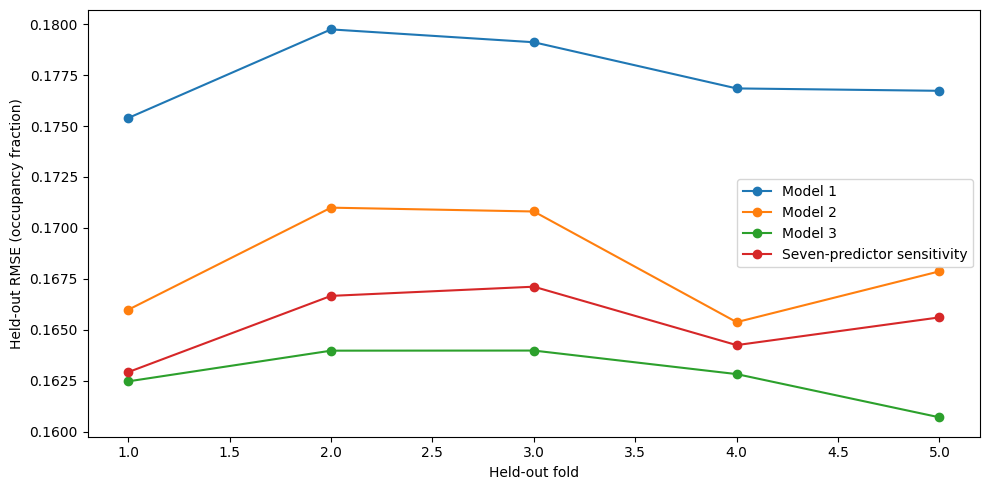

In [19]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
folds = KFold(n_splits=5, shuffle=True, random_state=10)
fits = {"Model 1": model1, "Model 2": model2, "Model 3": model3,
        "Seven-predictor sensitivity": legacy_model}
fold_errors = {}
for label, fit in fits.items():
    columns = [v for v in fit.model.exog_names if v != "const"]
    fold_errors[label] = -cross_val_score(LinearRegression(), data[columns], y,
                                        cv=folds, scoring="neg_root_mean_squared_error")
cv_results = pd.DataFrame(fold_errors, index=pd.Index(range(1, 6), name="Held-out fold"))
comparison = pd.DataFrame({
    label: {"Slopes": len(fit.params)-1, "N": int(fit.nobs), "R2": fit.rsquared,
            "Adjusted R2": fit.rsquared_adj, "AIC": fit.aic, "BIC": fit.bic,
            "In-sample RMSE": np.sqrt(np.mean(fit.resid**2)),
            "Mean 5-fold RMSE": fold_errors[label].mean(),
            "SD across folds": fold_errors[label].std(ddof=1)}
    for label, fit in fits.items()
}).T
display(cv_results.round(6))
display(comparison.round(6))
cv_results.plot(marker="o",figsize=(10,5))
plt.ylabel("Held-out RMSE (occupancy fraction)"); plt.tight_layout(); plt.show()


Each fold fits a fresh LinearRegression on training rows only; identical shuffled five-fold splits use seed 10. The significance screen and Boruta/Cp exploration precede this fixed-specification CV, so it is not nested validation of the entire selection procedure. Nearby spaces/tracts occur in both folds; this is held-out-space accuracy within the observed setting, not new-neighborhood or future-time performance.

<a id="section-3f"></a>

## 3(f) Final Model Selection and Justification


In [20]:
required = comparison.loc[["Model 1","Model 2","Model 3"]]
display(pd.Series({"Highest adjusted R2":required["Adjusted R2"].idxmax(),
                   "Lowest AIC":required["AIC"].idxmin(),"Lowest BIC":required["BIC"].idxmin(),
                   "Lowest CV RMSE":required["Mean 5-fold RMSE"].idxmin()}))
display(Markdown(f"Model 3 is carried forward with **{len(predictors)} slopes** on **{len(data):,} spaces**. Its adjusted R² is **{model3.rsquared_adj:.5f}**, AIC **{model3.aic:.2f}**, BIC **{model3.bic:.2f}**, and mean held-out RMSE **{fold_errors['Model 3'].mean():.5f}**. "))
table_dir = root/"reports/tables"; table_dir.mkdir(parents=True,exist_ok=True)
_export_chars = (table_dir/"current_model_comparison.json").write_text(comparison.to_json(orient="index",indent=2))


Highest adjusted R2    Model 3
Lowest AIC             Model 3
Lowest BIC             Model 3
Lowest CV RMSE         Model 3
dtype: object

Model 3 is carried forward with **7 slopes** on **4,016 spaces**. Its adjusted R² is **0.29291**, AIC **-3185.77**, BIC **-3135.39**, and mean held-out RMSE **0.16280**. 

In [21]:
delta_rmse = comparison.loc["Model 2", "Mean 5-fold RMSE"] - comparison.loc["Model 3", "Mean 5-fold RMSE"]
display(Markdown(f"Among the three competing specifications, Model 3 has the best displayed adjusted R², AIC, BIC and mean held-out RMSE. Its mean error improves over Model 2 by **{100 * delta_rmse:.3f} occupancy percentage points of RMSE**. It adds travel context, tariff structure and commercial composition to the parsimonious demand controls. This justifies carrying Model 3 forward, while the Cp comparison, correlated regressors, endogenous prices and post-selection uncertainty prevent treating it as a uniquely correct or causal model."))


Among the three competing specifications, Model 3 has the best displayed adjusted R², AIC, BIC and mean held-out RMSE. Its mean error improves over Model 2 by **0.541 occupancy percentage points of RMSE**. It adds travel context, tariff structure and commercial composition to the parsimonious demand controls. This justifies carrying Model 3 forward, while the Cp comparison, correlated regressors, endogenous prices and post-selection uncertainty prevent treating it as a uniquely correct or causal model.

The final specification follows the explicit full-candidate significance rule and represents price, density, travel context, tariff structure and commercial composition. Selection is justified by the displayed criteria among the three competing models, while the Cp optimum and seven-predictor sensitivity specification remain visible. Retaining both business counts makes the retail coefficient a composition association holding total registrations fixed. Neither good fit nor small p-values validates causality or the OLS assumptions; Section 4 checks them.